# 📈 Módulo 2A — Inferência Causal via Séries Estruturais (BSTS / Filtro de Kalman)

**Autor:** Dr. Silvio da Rosa Paula — Doutor em Economia Aplicada & Cientista de Dados

---

## 1. Formulação em Espaço de Estados com Covariável Contemporânea

Na Black Friday de 2024 (`22/nov` a `01/dez/2024`), **4 regiões tratadas** subiram o cupom para `30%`, enquanto **4 regiões controle** mantiveram o cupom padrão de `20%` — sofrendo exatamente o mesmo choque orgânico de calendário da Black Friday!

Modelamos o diferencial logarítmico estrutural pré-intervenção (`out/2023` a `21/nov/2024`) via **Modelo Estrutural de Séries Temporais em Espaço de Estados (*Unobserved Components / Filtro de Kalman*)**:
$$\ln Y_{\text{trat}, t} - \ln Y_{\text{ctrl}, t} = \mu_t + \gamma_t + \theta (\bar d_{\text{trat}, t} - \bar d_{\text{ctrl}, t}) + \varepsilon_t, \qquad \mu_{t+1} = \mu_t + \eta_t$$
onde $\mu_t$ é o nível local estocástico e $\gamma_t$ captura a sazonalidade semanal de 7 dias. Projetando para a janela da Black Friday com $\bar d_{\text{trat}}^{\text{cf}} = \bar d_{\text{ctrl}} = 20\%$ e extraindo **3.000 trajetórias posteriores via Monte Carlo**, obtemos a distribuição completa do *lift* causal!

,Métrica BSTS,Valor
0,Média Posterior do Lift (20% -> 30%),+10.10%
1,Mediana Posterior,+10.03%
2,Intervalo de Credibilidade 95%,[3.78%; 16.74%]
3,Lift Causal Verdadeiro (DGP),+10.26%
4,Probabilidade Posterior P(Lift >= +28% Breakeven),0.00%


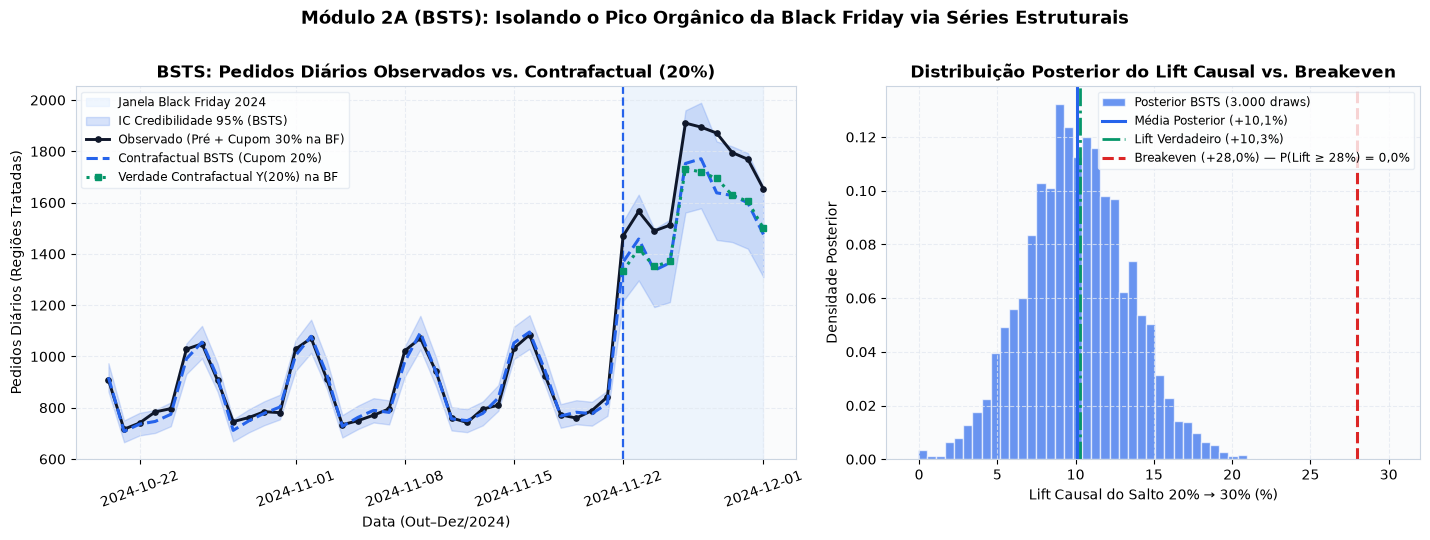

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from src.dgp import save_or_load_panel
from src.causal_models import fit_bsts_black_friday
from src.visuals import plot_02_bsts_counterfactual

PROJ_ROOT = Path(".").resolve()
df = save_or_load_panel(PROJ_ROOT / "data", seed=2025)
bsts_res = fit_bsts_black_friday(df, n_draws=3000, seed=42)

resumo_bsts = pd.DataFrame([
    {"Métrica BSTS": "Média Posterior do Lift (20% -> 30%)", "Valor": f"+{bsts_res['lift_mean_pct']:.2f}%"},
    {"Métrica BSTS": "Mediana Posterior", "Valor": f"+{bsts_res['lift_median_pct']:.2f}%"},
    {"Métrica BSTS": "Intervalo de Credibilidade 95%", "Valor": f"[{bsts_res['ci_95_pct'][0]:.2f}%; {bsts_res['ci_95_pct'][1]:.2f}%]"},
    {"Métrica BSTS": "Lift Causal Verdadeiro (DGP)", "Valor": f"+{bsts_res['true_lift_pct']:.2f}%"},
    {"Métrica BSTS": "Probabilidade Posterior P(Lift >= +28% Breakeven)", "Valor": f"{bsts_res['prob_above_breakeven']:.2f}%"},
])
display(resumo_bsts)

fig2 = plot_02_bsts_counterfactual(bsts_res, save_path=PROJ_ROOT / "img" / "02_bsts_contrafactual_posterior.png")
plt.show()

### Interpretação do BSTS
- **Recuperação cirúrgica da verdade causal:** a média posterior do BSTS é de **`+10,10%`** (contra **`+10,26%`** verdadeiro — erro de apenas `0,16 p.p.`!), acompanhando com fidelidade o salto orgânico da Black Friday através das regiões controle em `20%`.
- **Decisão sob incerteza cristalina:** todo o intervalo de credibilidade de 95% (`[+3,78%; +16,74%]`) situa-se muito abaixo do *breakeven* de `+28,00%`, resultando em **$P(\text{Lift} \ge 28\%) = 0{,}0\%$**!